In [4]:
import xarray as xr

whacs_ds = (
    xr.open_zarr("inputs/WHACS/processed/WHACS_NorthCarolina.zarr")
    .sel(time="1986-01")
    .load()
)
whacs_ds

<xarray.Dataset> Size: 3MB
Dimensions:                      (time: 744, goal: 14)
Coordinates:
  * time                         (time) datetime64[ns] 6kB 1986-01-01 ... 198...
  * goal                         (goal) int64 112B 1 2 3 4 5 ... 10 11 12 13 14
    latitude                     (goal) float32 56B 36.56 36.12 ... 33.0 32.88
    longitude                    (goal) float32 56B -75.5 -75.25 ... -79.0
    seapoint                     (goal) int32 56B 1904482 1904397 ... 1903044
Data variables: (12/39)
    cge                          (time, goal) float64 83kB 2.7 3.3 ... 0.8 0.7
    dir                          (time, goal) float64 83kB 173.5 181.7 ... 83.2
    dp                           (time, goal) float64 83kB 173.0 181.0 ... 103.0
    fp                           (time, goal) float64 83kB 0.228 0.217 ... 0.095
    hs                           (time, goal) float64 83kB 1.042 1.152 ... 0.438
    pdir0                        (time, goal) float64 83kB 183.6 192.0 ... 68.5
    ...                           ...
    ptp3                         (time, goal) float64 83kB nan 10.21 ... 7.55
    spr                          (time, goal) float64 83kB 37.0 37.3 ... 25.6
    t01                          (time, goal) float64 83kB 3.88 4.06 ... 4.82
    t02                          (time, goal) float64 83kB 3.47 3.64 ... 3.96
    uwnd                         (time, goal) float64 83kB 4.4 4.5 ... -3.2 -3.3
    vwnd                         (time, goal) float64 83kB 7.2 7.5 ... 0.5 0.7
Attributes: (12/59)
    Conventions:                     CF-1.11 ACDD-1.3
    title:                           Wave Hindcast for the Australian Climate...
    summary:                         Wave Hindcast for the Australian Climate...
    keywords:                        WHACS, ACS, waves, ocean, coast, WWIII, ...
    id:                              BoM-CSIRO-WHACS-001
    naming_authority:                au.csiro
    ...                              ...
    geospatial_lon_max:              179.9375
    geospatial_vertical_positive:    up
    time_coverage_start:             1979-01-01T00:00:00
    time_coverage_end:               1979-01-31T23:00:00
    time_coverage_duration:          P30DT23H0M0S
    time_coverage_resolution:        P0DT1H0M0S

In [5]:
import pandas as pd

metamodel_parameters = {
    "hs_goals": [
        whacs_ds.hs.isel(time=itime).values.tolist()
        for itime in range(len(whacs_ds.time))
    ],
    "tp_goals": [
        (1.0 / whacs_ds.fp.isel(time=itime).values).tolist()
        for itime in range(len(whacs_ds.time))
    ],
    "wd_goals": [
        whacs_ds.dir.isel(time=itime).values.tolist()
        for itime in range(len(whacs_ds.time))
    ],
    "ds_goals": [
        whacs_ds.spr.isel(time=itime).values.tolist()
        for itime in range(len(whacs_ds.time))
    ],
    "tref": pd.to_datetime(whacs_ds.time.values).strftime("%Y%m%d %H%M%S").tolist(),
}
metamodel_parameters.keys()

dict_keys(['hs_goals', 'tp_goals', 'wd_goals', 'ds_goals', 'tref'])

In [6]:
from utils.config import GOALS
from utils.snapwave_wrapper import SnapWaveDynamicModelWrapper

snapwave_wrapper = SnapWaveDynamicModelWrapper(
    templates_dir="templates-dynamic",
    metamodel_parameters=metamodel_parameters,
    fixed_parameters={},
    output_dir="SnapWave_CASES_Dynamic",
    aoi_file="inputs/AoI_Polygons/AoI_NorthCarolina.shp",
    goals_config=GOALS,
)
snapwave_wrapper

2026-06-16 14:34:35,608 - SnapWaveDynamicModelWrapper - WARNING - Parameter hs_goals is not in the default_parameters
2026-06-16 14:34:35,609 - SnapWaveDynamicModelWrapper - WARNING - Parameter tp_goals is not in the default_parameters
2026-06-16 14:34:35,609 - SnapWaveDynamicModelWrapper - WARNING - Parameter wd_goals is not in the default_parameters
2026-06-16 14:34:35,610 - SnapWaveDynamicModelWrapper - WARNING - Parameter ds_goals is not in the default_parameters
2026-06-16 14:34:35,610 - SnapWaveDynamicModelWrapper - WARNING - Parameter tref is not in the default_parameters


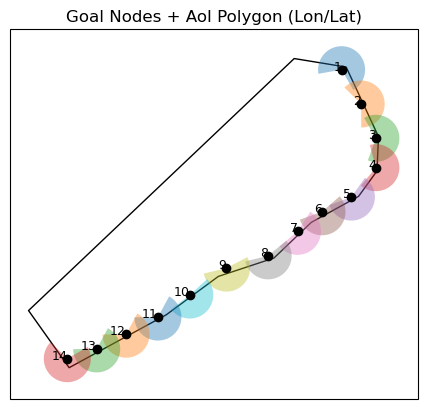

In [7]:
snapwave_wrapper.plot_configuration()

In [8]:
snapwave_wrapper.build_cases(cases_name_format=lambda ctx: f"{ctx.get('tref')}")

In [9]:
snapwave_wrapper.run_cases_in_background(launcher="default", num_workers=2)

In [11]:
snapwave_wrapper.monitor_cases(value_counts="simple")

Status     
NOT STARTED    526
FINISHED       216
RUNNING          2
Name: count, dtype: int64

In [12]:
result = snapwave_wrapper.postprocess_cases()
result

<xarray.Dataset> Size: 6MB
Dimensions:       (time: 744, stations: 338)
Coordinates:
  * time          (time) datetime64[ns] 6kB 2023-01-01 ... 2023-01-31T23:00:00
    station_name  (stations) |S256 87kB b'station_0001                    ' ....
    station_x     (stations) float32 1kB -76.23 -76.19 -76.14 ... -79.19 -77.95
    station_y     (stations) float32 1kB 37.0 36.99 36.98 ... 33.65 33.35 34.23
    point_zb      (stations) float32 1kB nan nan nan nan nan ... nan nan nan nan
Dimensions without coordinates: stations
Data variables:
    point_zs      (time, stations) float32 1MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 1.372
    point_hm0     (time, stations) float32 1MB 0.0 0.0 0.0 ... 0.6289 0.0 0.7779
    point_tp      (time, stations) float32 1MB 0.0 0.0 0.0 ... 11.64 0.0 11.64
    point_wavdir  (time, stations) float32 1MB 270.0 270.0 270.0 ... 270.0 103.2
    point_dw      (time, stations) float32 1MB 0.0 0.0 0.0 ... 0.0 1.535e-32
    point_df      (time, stations) float32 1MB 0.0 0.0 0.0 ... 0.0 0.04246
Attributes:
    Conventions:                         Conventions = 'CF-1.6, SGRID-0.3
    Build-Revision-Date-Netcdf-library:  4.9.2 of Mar 31 2024 08:09:36 $
    Producer:                            SnapWave
    title:                               Snapwave his point netcdf output

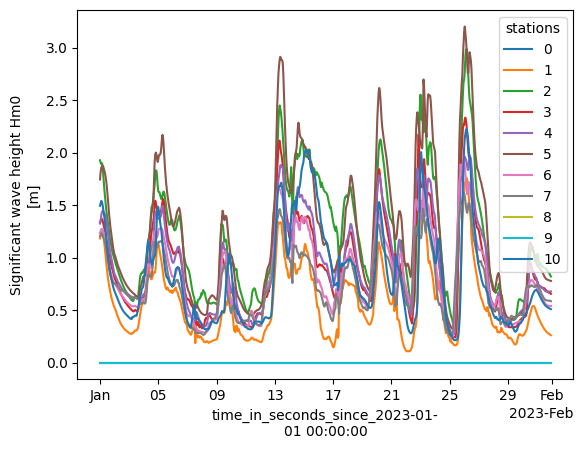

In [13]:
result.point_hm0.isel(stations=slice(None, None, 33)).plot(hue="stations");

In [ ]:
result.to_netcdf("SnapWave_CASES_Dynamic/Dynamic_Cases_198601.nc")